[0.071 0.081 0.091 0.101 0.111 0.121 0.131 0.141 0.151 0.161 0.171]
338.6641321834696 -0.012279729838385434


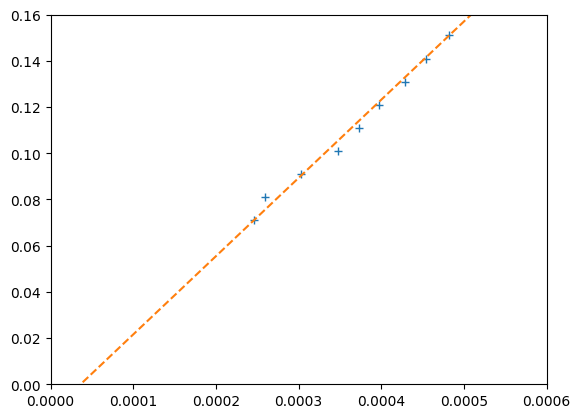

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

d = np.array( [5.1, 6.1, 7.1, 8.1, 9.1, 10.1, 11.1, 12.1, 13.1, 14.1, 15.1] )*1e-2
Delta_T = np.array( [274, 288, 336, 386, 414, 442, 476, 504, 536, 562, 592] )*0.9e-6

plt.plot( Delta_T, d, ls='', marker='+' )

a, b, r2, *_ = linregress( Delta_T, d )

Delta_T_lin = np.array( [0, np.max(Delta_T) ] )
plt.plot( Delta_T_lin, a*Delta_T_lin+b, ls='--' )

print( d )
print( a, b)

plt.ylim( 0, 16e-2 )
plt.xlim( 0, 600e-6 )
plt.show()


## Etude des transducteurs ultrasonores

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from scipy.fft import fft, fftshift, fftfreq

In [38]:
f = 40e3
dt = 1/(10*f)  # Pas d'échantillonnage en secondes
t = np.arange(0, 30/f, dt )

Text(0.5, 0, 'fréquence (Hz)')

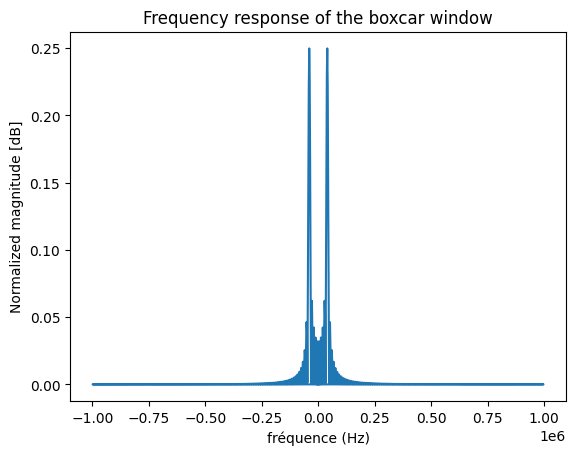

In [27]:
A = fft(e, 1000) / (len(e)/2.0)
freq = fftfreq(e.size, t[1])
response = 20 * np.log10(np.abs(fftshift(A / abs(A).max())))
plt.plot(freq, np.abs(A) )

plt.title("Frequency response of the boxcar window")
plt.ylabel("Normalized magnitude [dB]")
plt.xlabel("fréquence (Hz)")

In [88]:
from importLTP import ReadLTP

nom = 'tp_ultrason.ltp'
data = ReadLTP( nom )

Courbes disponibles :
 num |   x   |   y
--------------------------
   0 | Temps | EA0       
   1 | Temps | EA1       


(0.0, 0.002)

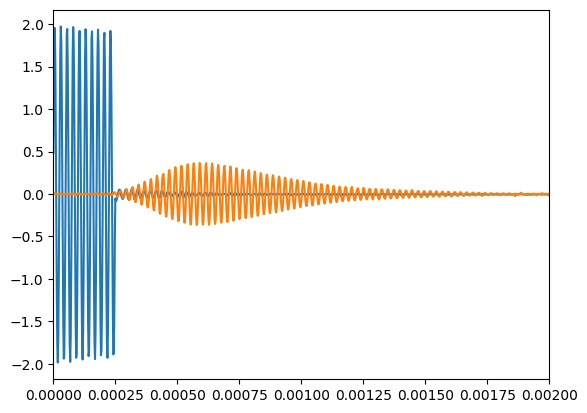

In [92]:
t = data.courbe( 0 )['x']
E = data.courbe( 0 )['y']
S = data.courbe( 1 )['y']
plt.plot( t, E)
plt.plot( t, S )
plt.xlim(0, 2e-3)

C:\Users\grego\AppData\Local\Temp\ipykernel_44376\3691146203.py:9: RuntimeWarning: divide by zero encountered in divide
  H = lambda f : 1/(1+Q*1j*(f/f0-f0/f))
C:\Users\grego\AppData\Local\Temp\ipykernel_44376\3691146203.py:9: RuntimeWarning: invalid value encountered in multiply
  H = lambda f : 1/(1+Q*1j*(f/f0-f0/f))
C:\Users\grego\AppData\Local\Temp\ipykernel_44376\3691146203.py:9: RuntimeWarning: invalid value encountered in divide
  H = lambda f : 1/(1+Q*1j*(f/f0-f0/f))


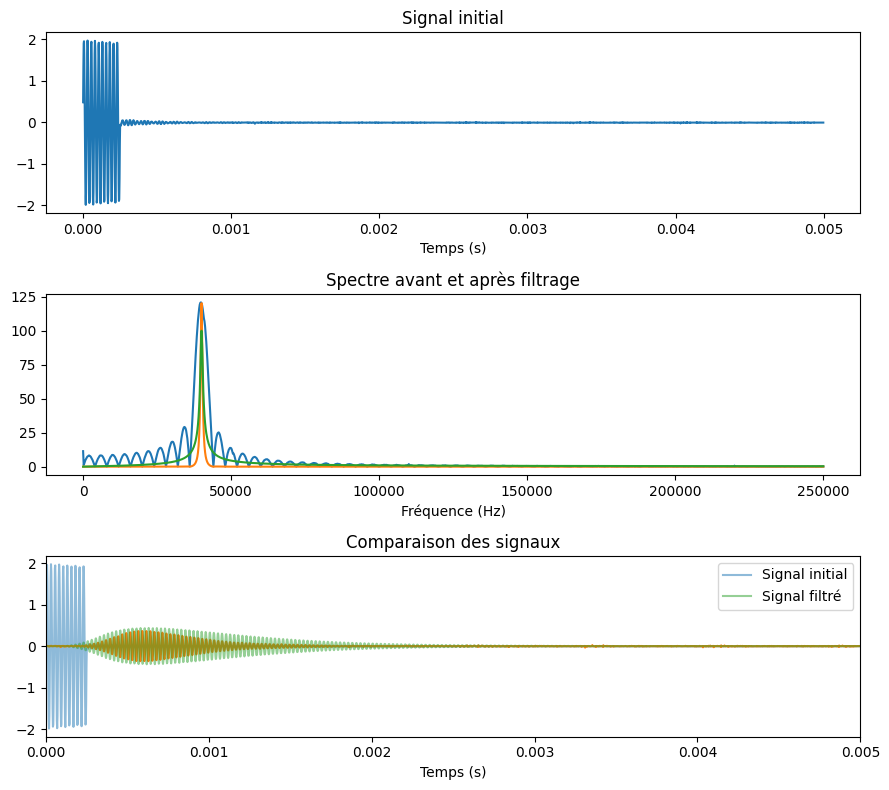

In [121]:
# 1. Transformée de Fourier
dt = t[1]
Efft = np.fft.rfft(E)
f = np.fft.rfftfreq(len(E), d=dt)

# 2. Filtre linéaire : filtre passe-bas idéal
f0 = 40e3
Q = 50
H = lambda f : 1/(1+Q*1j*(f/f0-f0/f))

FCT = H(f)
FCT[0]=0

tau = 1e-4 # Retard
c = 340

Y_filtre = Efft * FCT**2 *np.exp(-1j*tau*2*np.pi*f)

# 3. Transformée de Fourier inverse
E_filtre = np.fft.irfft(Y_filtre, n=len(E))

# 4. Affichage des résultats
fig, axes = plt.subplots(3, 1, figsize=(9, 8))

axes[0].plot(t, E)
axes[0].set_title("Signal initial")
axes[0].set_xlabel("Temps (s)")

axes[1].plot(f, np.abs(Efft))
axes[1].plot(f, np.abs(Y_filtre))
axes[1].plot(f, 100*np.abs(FCT))
axes[1].set_title("Spectre avant et après filtrage")
axes[1].set_xlabel("Fréquence (Hz)")

axes[2].plot(t, E, alpha=0.5, label="Signal initial")
axes[2].plot(t, S)
axes[2].plot(t, E_filtre, alpha=0.5, label="Signal filtré")
axes[2].set_title("Comparaison des signaux")
axes[2].set_xlabel("Temps (s)")
axes[2].set_xlim(0, 5e-3)
axes[2].legend()

plt.tight_layout()
plt.show()

In [122]:
dt = t[1]
Efft = np.fft.rfft(E)
Sfft = np.fft.rfft(S)
f = np.fft.rfftfreq(len(E), d=dt)

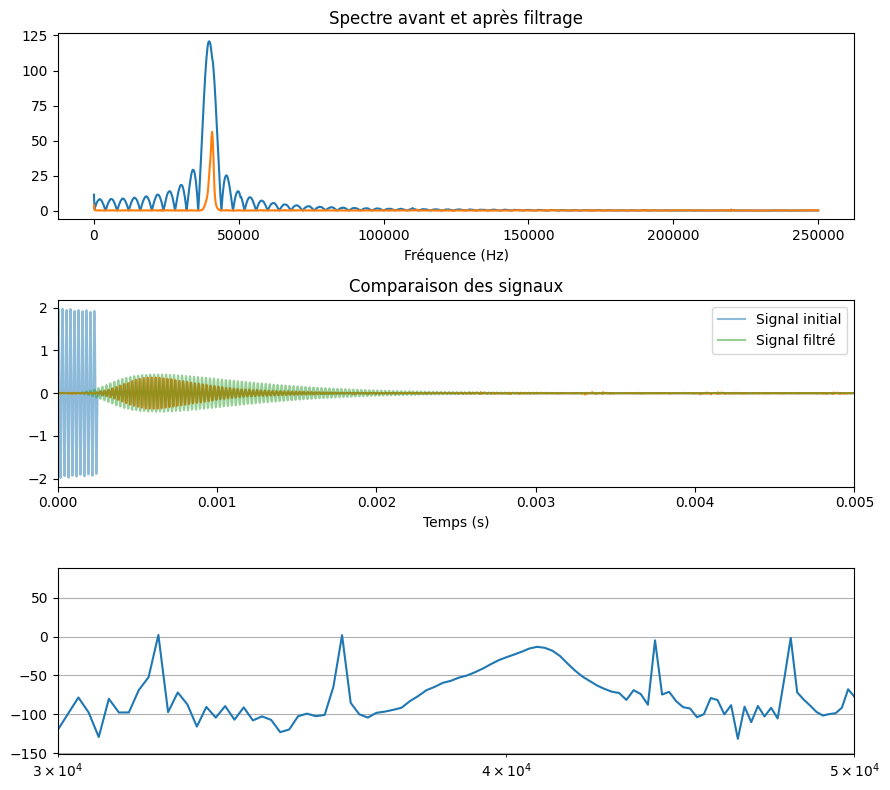

In [133]:
# 4. Affichage des résultats
fig, axes = plt.subplots(3, 1, figsize=(9, 8))

axes[0].plot(f, np.abs(Efft))
axes[0].plot(f, np.abs(Sfft))
axes[0].set_title("Spectre avant et après filtrage")
axes[0].set_xlabel("Fréquence (Hz)")

axes[1].plot(t, E, alpha=0.5, label="Signal initial")
axes[1].plot(t, S)
axes[1].plot(t, E_filtre, alpha=0.5, label="Signal filtré")
axes[1].set_title("Comparaison des signaux")
axes[1].set_xlabel("Temps (s)")
axes[1].set_xlim(0, 5e-3)
axes[1].legend()

axes[2].semilogx( f, 20*np.log(np.abs(Sfft/Efft)) )
axes[2].set_xlim(30e3, 50e3 )
axes[2].grid()

plt.tight_layout()
plt.show()